# Jupyter Notebook for Exploratory Data Analysis

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
import numpy as np



In [4]:
df = pd.read_parquet("../../data_pipeline/data/processed/season_12325_clean.parquet")
print(df.head())

                      seasonGoals_overall  seasonConceded_overall  \
name                                                                
Arsenal FC                             69                      34   
Tottenham Hotspur FC                   64                      65   
Manchester City FC                     72                      44   
Leicester City FC                      33                      80   
Crystal Palace FC                      51                      51   

                      seasonGoalsTotal_overall  seasonScoredNum_overall  \
name                                                                      
Arsenal FC                                 103                       69   
Tottenham Hotspur FC                       129                       64   
Manchester City FC                         116                       72   
Leicester City FC                          113                       33   
Crystal Palace FC                          102                    

## Checking for missing/ incomplete data

In [5]:
missing = df.isnull().sum()
missing_cols = missing[missing > 0].sort_values(ascending=False)
print(missing_cols)

Series([], dtype: int64)


## Descriptive Statistics

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
seasonGoals_overall,20.0,55.75,14.707231,26.0,45.50,58.0,66.00,86.0
seasonConceded_overall,20.0,55.75,14.421749,34.0,45.50,52.5,62.75,86.0
seasonGoalsTotal_overall,20.0,111.50,10.831241,86.0,104.00,110.5,119.25,129.0
seasonScoredNum_overall,20.0,55.75,14.707231,26.0,45.50,58.0,66.00,86.0
seasonConcededNum_overall,20.0,55.75,14.421749,34.0,45.50,52.5,62.75,86.0
...,...,...,...,...,...,...,...,...
additional_info.freekicks_total_over265_overall,20.0,31.30,19.876196,0.0,20.00,28.0,41.00,71.0
additional_info.freekicks_total_over275_overall,20.0,27.90,19.633216,0.0,16.25,28.0,35.50,71.0
additional_info.freekicks_total_over285_overall,20.0,21.50,14.827073,0.0,13.75,20.5,25.50,56.0
additional_info.freekicks_total_over295_overall,20.0,17.10,11.561734,0.0,7.75,19.0,22.25,43.0


## Variance and Correlation Check

In [7]:
# Low variance columns are not useful for PCA or clustering
low_variance = df.var().sort_values()
print("Low variance features:\n", low_variance.head())

# Correlation matrix (optional: subset of top features to keep it readable)
corr = df.corr()
print(corr.shape)

# If you want to see the strongest relationships:
top_corr = corr.unstack().sort_values(ascending=False)
top_corr = top_corr[top_corr != 1]  # drop self-correlations
top_corr.head(10)


Low variance features:
 additional_info.penalties_recorded_matches_overall    0.0
cornersRecorded_matches_overall                       0.0
over85CardsPercentage_overall                         0.0
over75CardsPercentage_overall                         0.0
over75Cards_overall                                   0.0
dtype: float64
(543, 543)


over65CardsFor_overall            over65CardsForPercentage_overall    1.000000
over65CardsForPercentage_overall  over65CardsFor_overall              1.000000
dangerous_attacks_avg_overall     dangerous_attacks_num_overall       1.000000
dangerous_attacks_num_overall     dangerous_attacks_avg_overall       1.000000
attacks_avg_overall               attacks_num_overall                 1.000000
attacks_num_overall               attacks_avg_overall                 1.000000
shotsTotal_overall                shotsAVG_overall                    0.999999
shotsAVG_overall                  shotsTotal_overall                  0.999999
foulsAVG_overall                  foulsTotal_overall                  0.999998
foulsTotal_overall                foulsAVG_overall                    0.999998
dtype: float64

## Feature Redundancy Removal. 
We have several columns that are identical so we will be removing columns with a certain level of correlation along with columns with a correlation score of 0. 

In [8]:

# --- STEP 1: Drop near-identical numeric columns ---
corr_matrix = df.corr(numeric_only=True).abs()

# Mask the upper triangle to avoid duplicate checks
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Set threshold for almost perfect correlation
THRESHOLD = 0.9999

# Identify columns to drop
to_drop_corr = [col for col in upper.columns if any(upper[col] > THRESHOLD)]

print(f"Dropping {len(to_drop_corr)} highly correlated columns (>{THRESHOLD})...")
if to_drop_corr:
    print(f"Examples: {to_drop_corr[:10]}")

# Drop directly from df
df.drop(columns=to_drop_corr, errors="ignore", inplace=True)
print(f"After correlation filter → {df.shape[1]} columns remain.")

# --- STEP 2: Drop low-variance columns ---
numeric_cols = df.select_dtypes(include=[np.number]).columns

selector = VarianceThreshold(threshold=0.0001)
selector.fit(df[numeric_cols])

# Determine which numeric columns to keep
kept_numeric = numeric_cols[selector.get_support()]
drop_low_var = list(set(numeric_cols) - set(kept_numeric))

print(f"Dropping {len(drop_low_var)} low-variance columns...")
if drop_low_var:
    print(f"Examples: {drop_low_var[:10]}")

# Drop directly from df
df.drop(columns=drop_low_var, errors="ignore", inplace=True)

print(f"Final DataFrame shape: {df.shape}")

Dropping 55 highly correlated columns (>0.9999)...
Examples: ['seasonScoredNum_overall', 'seasonConcededNum_overall', 'seasonAVG_overall', 'seasonScoredAVG_overall', 'seasonConcededAVG_overall', 'losePercentage_overall', 'HTPPG_overall', 'scoredGoalsHT_overall', 'GoalsHT_overall', 'seasonUnder55Percentage_overall']
After correlation filter → 488 columns remain.
Dropping 14 low-variance columns...
Examples: ['additional_info.penalties_recorded_matches_overall', 'additional_info.shots_recorded_matches_num_overall', 'over75CardsPercentage_overall', 'attack_num_recoded_matches_overall', 'seasonMatchesPlayedGoalTimingRecorded_overall', 'over85CardsPercentage_overall', 'additional_info.fouls_recorded_overall', 'over75Cards_overall', 'cornersRecorded_matches_overall', 'additional_info.cardsRecorded_matches_overall']
Final DataFrame shape: (20, 474)


## Checking for inconsistent data types
Everything is as it should be

In [9]:
# Inspect current data types
print("Data type summary:")
print(df.dtypes.value_counts())

# Identify columns with mixed or inconsistent types
# (object columns often hide numeric or mixed data)
object_cols = df.select_dtypes(include="object").columns

print(f"\nFound {len(object_cols)} object-type columns to inspect:")

for col in object_cols:
    sample_values = df[col].dropna().unique()[:5]  # quick peek
    print(f"{col}: sample values → {sample_values}")

# Optional: try converting 'numeric-looking' object columns to numeric
for col in object_cols:
    try:
        df[col] = pd.to_numeric(df[col], errors="ignore")
    except Exception as e:
        print(f"⚠️ Skipped {col}: {e}")

# Recheck types after conversion
print("\n✅ After normalization, data types:")
print(df.dtypes.value_counts())

Data type summary:
int64      441
float64     33
Name: count, dtype: int64

Found 0 object-type columns to inspect:

✅ After normalization, data types:
int64      441
float64     33
Name: count, dtype: int64


## Checking outliers
Outliers are completely normal within the realm of sports so I decided to not drop any of the outliers in respect to the nature of the sport 
38+ games per team x 20 teams = 720+ games


Top 10 features with most outliers:
over75Corners_overall                   6
over75CornersPercentage_overall         6
over65CardsFor_overall                  5
over65CardsAgainst_overall              4
over65CardsAgainstPercentage_overall    4
seasonBTTS_overall                      4
scored_2hg_avg_overall                  4
fts_2hg_overall                         4
fts_2hg_percentage_overall              4
corners_fh_over6_percentage_overall     4
dtype: int64


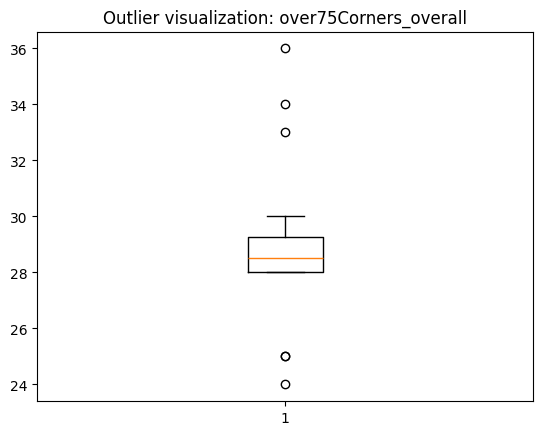

In [10]:
numeric_df = df.select_dtypes(include=[np.number])

# Use Interquartile Range (IQR) method to detect outliers
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

outlier_mask = ((numeric_df < (Q1 - 1.5 * IQR)) | (numeric_df > (Q3 + 1.5 * IQR)))
outlier_counts = outlier_mask.sum().sort_values(ascending=False)

print("\nTop 10 features with most outliers:")
print(outlier_counts.head(10))

col = outlier_counts.index[0]  # most outlier-heavy column
plt.boxplot(df[col].dropna())
plt.title(f"Outlier visualization: {col}")
plt.show()



## Checking for invalid data types. 
Everything is as it should be. Negatives where there should be negatives.

In [11]:
# 1. Check for negative values where they don't make sense
neg_cols = [col for col in df.select_dtypes(include=[np.number]).columns if (df[col] < 0).any()]
print(f"Columns containing negative values: {neg_cols if neg_cols else 'None'}")

# 2. Check for values above 100 in percentage-related columns
pct_cols = [col for col in df.columns if 'percent' in col.lower() or 'pct' in col.lower()]
pct_invalid = {col: (df[col] > 100).sum() for col in pct_cols if (df[col] > 100).any()}
print(f"\nPercentage columns exceeding 100%: {pct_invalid if pct_invalid else 'None'}")

# 3. Check for infinities or NaNs after any previous transformations
infinite_cols = [col for col in df.columns if np.isinf(df[col]).any()]
nan_cols = [col for col in df.columns if df[col].isna().any()]

print(f"\nColumns with infinite values: {infinite_cols if infinite_cols else 'None'}")
print(f"Columns with missing values (NaNs): {len(nan_cols)}")

Columns containing negative values: ['seasonGoalDifference_overall', 'GoalDifferenceHT_overall', 'gd_2hg_overall']

Percentage columns exceeding 100%: None

Columns with infinite values: None
Columns with missing values (NaNs): 0


# Univariate Analysis
1. Numerical Summary
2. Visualize Single Variable Distributions
3. Univariate Categorical Summaries
4. Indetify Skewed Features for Transformation
5. Summarize

In [12]:
# Numeric feature summary
num_summary = df.describe().T
num_summary["missing_values"] = df.isna().sum()
num_summary["skew"] = df.skew()
num_summary["kurtosis"] = df.kurt()

# Sort by standard deviation or skew if you want to spot odd distributions
num_summary = num_summary.sort_values("skew", ascending=False)

display(num_summary.head(5))

num_summary = num_summary.sort_values("kurtosis", ascending=False)
display(num_summary.head(5))



,count,mean,std,min,25%,50%,75%,max,missing_values,skew,kurtosis
over65CardsAgainst_overall,20.0,0.25,0.550120,0.0,0.0,0.0,0.0,2.0,0,2.239302,4.656511
over65CardsAgainstPercentage_overall,20.0,0.70,1.490320,0.0,0.0,0.0,0.0,5.0,0,1.952569,2.752885
cornersLowest_overall,20.0,0.50,0.827170,0.0,0.0,0.0,1.0,3.0,0,1.859909,3.443323
seasonScoredMin_overall,20.0,66.60,22.222322,40.0,52.0,59.0,75.0,132.0,0,1.645646,2.890830
additional_info.win_0_10_num_overall,20.0,4.00,1.973509,1.0,3.0,3.5,5.0,10.0,0,1.460791,3.442337


,count,mean,std,min,25%,50%,75%,max,missing_values,skew,kurtosis
additional_info.match_shots_on_target_over75_num_overall,20.0,26.20,3.122078,16.0,25.75,27.0,28.25,30.0,0,-1.935633,5.319597
additional_info.match_shots_on_target_over75_percentage_overall,20.0,68.75,8.264541,42.0,67.50,71.0,74.50,79.0,0,-1.902393,5.075055
over65CardsAgainst_overall,20.0,0.25,0.550120,0.0,0.00,0.0,0.00,2.0,0,2.239302,4.656511
cornersLowest_overall,20.0,0.50,0.827170,0.0,0.00,0.0,1.00,3.0,0,1.859909,3.443323
additional_info.win_0_10_num_overall,20.0,4.00,1.973509,1.0,3.00,3.5,5.00,10.0,0,1.460791,3.442337


# In Depth Review of flagged columns

In [13]:

# Numeric only
num_df = df.select_dtypes(include=[np.number])

# Compute both metrics
shape_df = pd.DataFrame({
    "skew": num_df.skew(),
    "kurtosis": num_df.kurt()
})
shape_df["abs_skew"] = shape_df["skew"].abs()
shape_df["abs_kurt"] = shape_df["kurtosis"].abs()

# Sort by most non-normal features
shape_df["non_normal_score"] = shape_df["abs_skew"] + shape_df["abs_kurt"]
shape_df = shape_df.sort_values("non_normal_score", ascending=False)

print(f"{shape_df.shape[0]} numeric features analyzed.")
shape_df.head(15)

474 numeric features analyzed.


,skew,kurtosis,abs_skew,abs_kurt,non_normal_score
additional_info.match_shots_on_target_over75_num_overall,-1.935633,5.319597,1.935633,5.319597,7.255230
additional_info.match_shots_on_target_over75_percentage_overall,-1.902393,5.075055,1.902393,5.075055,6.977448
over65CardsAgainst_overall,2.239302,4.656511,2.239302,4.656511,6.895813
cornersLowest_overall,1.859909,3.443323,1.859909,3.443323,5.303232
additional_info.win_0_10_num_overall,1.460791,3.442337,1.460791,3.442337,4.903127
over65CardsAgainstPercentage_overall,1.952569,2.752885,1.952569,2.752885,4.705454
seasonScoredMin_overall,1.645646,2.890830,1.645646,2.890830,4.536475
additional_info.win_0_10_percentage_overall,1.351962,3.001113,1.351962,3.001113,4.353074
additional_info.penalty_in_a_match_percentage_overall,1.301871,3.028211,1.301871,3.028211,4.330082
over35OffsidesPercentage_overall,-1.223118,3.050850,1.223118,3.050850,4.273968


In [14]:
# Define thresholds
SKEW_LIMIT = 1.0
KURT_LIMIT = 2.0

interesting = shape_df[
    (shape_df["abs_skew"] > SKEW_LIMIT) | (shape_df["abs_kurt"] > KURT_LIMIT)
]

print(f"⚠️  Found {len(interesting)} features with high skew or kurtosis.")
display(interesting.head(5))

⚠️  Found 37 features with high skew or kurtosis.


,skew,kurtosis,abs_skew,abs_kurt,non_normal_score
additional_info.match_shots_on_target_over75_num_overall,-1.935633,5.319597,1.935633,5.319597,7.255230
additional_info.match_shots_on_target_over75_percentage_overall,-1.902393,5.075055,1.902393,5.075055,6.977448
over65CardsAgainst_overall,2.239302,4.656511,2.239302,4.656511,6.895813
cornersLowest_overall,1.859909,3.443323,1.859909,3.443323,5.303232
additional_info.win_0_10_num_overall,1.460791,3.442337,1.460791,3.442337,4.903127


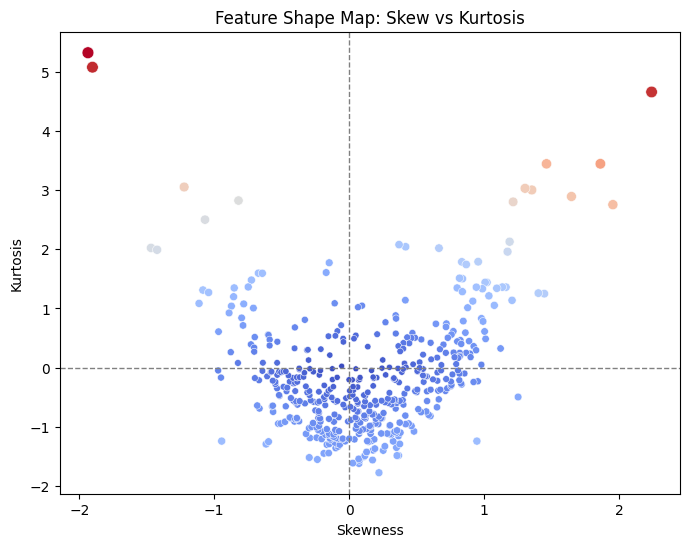

In [15]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=shape_df, x="skew", y="kurtosis",
    size="non_normal_score", hue="non_normal_score",
    palette="coolwarm", legend=False
)
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Feature Shape Map: Skew vs Kurtosis")
plt.xlabel("Skewness")
plt.ylabel("Kurtosis")
plt.show()


In [16]:
def classify_shape(row):
    s, k = row["skew"], row["kurtosis"]
    if abs(s) <= 1 and abs(k) <= 2:
        return "normalish"
    if abs(s) > 1 and abs(k) <= 2:
        return "skewed"
    if abs(s) <= 1 and k > 2:
        return "heavy_tailed"
    if abs(s) <= 1 and k < -1:
        return "flat"
    if abs(s) > 1 and k > 2:
        return "skewed_heavy"
    return "other"

shape_df["shape_type"] = shape_df.apply(classify_shape, axis=1)
interesting = shape_df.loc[shape_df.index.intersection(df.columns)]
interesting_subset = interesting.loc[interesting.index.isin(interesting.index[:37])]  # or filter by abs threshold
interesting_subset["shape_type"].value_counts()


shape_type
skewed_heavy    14
skewed          12
normalish        7
heavy_tailed     4
Name: count, dtype: int64

In [17]:
# Save your shape summary with shape_type classification
feature_shape_log = shape_df.reset_index().rename(columns={"index": "feature"})
feature_shape_log.to_csv("interesting_features/feature_shape_log.csv", index=False)

# Extract just the statistically interesting ones
interesting_features = feature_shape_log[
    feature_shape_log["shape_type"].isin(["skewed_heavy", "skewed", "heavy_tailed"])
]

interesting_features.to_csv("interesting_features/interesting_features.csv", index=False)

print(f"Saved {len(interesting_features)} statistically interesting features.")


Saved 37 statistically interesting features.


Decided to keep record of what columns are marked as "interesting" and would require further attention in the modeling stages. Nothing was flagged as an encoding error or data record error. Just interesting variables that we could gain some valuable insights from

# Bi Variate Analysis


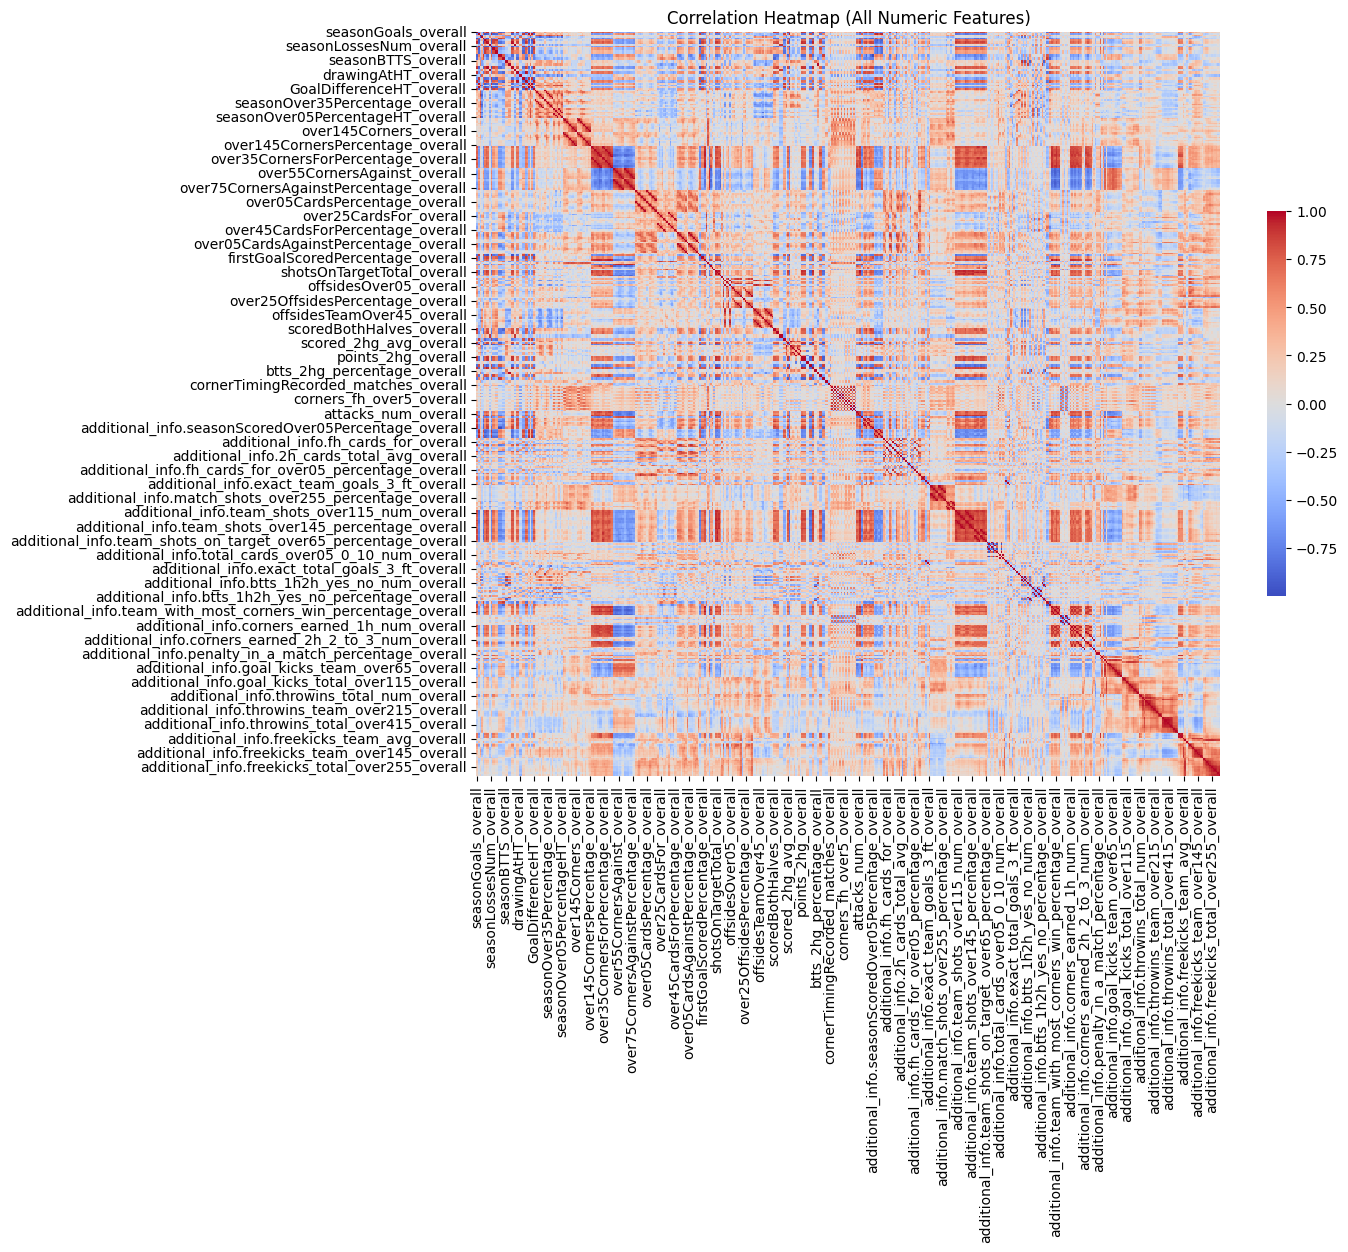

In [18]:
# Select numeric columns
num_df = df.select_dtypes(include=[np.number])

# Compute correlation matrix
corr = num_df.corr()

# Visualize top correlations ( too dense to see anything, so we need to zoom in)
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={'shrink': 0.5})
plt.title("Correlation Heatmap (All Numeric Features)")
plt.show()

In [19]:
# Flatten and sort correlation pairs
corr_pairs = (
    corr.abs()
    .unstack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "corr"})
)

# Remove self-correlations
corr_pairs = corr_pairs[corr_pairs["feature_1"] != corr_pairs["feature_2"]]

# Sort by strength
strong_corrs = corr_pairs.sort_values("corr", ascending=False)
strong_corrs.head(10)


,feature_1,feature_2,corr
16623,concededGoalsHT_overall,concededAVGHT_overall,0.999899
15677,concededAVGHT_overall,concededGoalsHT_overall,0.999899
64593,over15CardsAgainstPercentage_overall,over15CardsAgainst_overall,0.999893
61282,over15CardsAgainst_overall,over15CardsAgainstPercentage_overall,0.999893
10909,winPercentage_overall,seasonWinsNum_overall,0.999838
3341,seasonWinsNum_overall,winPercentage_overall,0.999838
119463,additional_info.seasonScoredOver05Percentage_o...,seasonFTSPercentage_overall,0.999832
7362,seasonFTSPercentage_overall,additional_info.seasonScoredOver05Percentage_o...,0.999832
8074,seasonFTSPercentageHT_overall,seasonFTSHT_overall,0.999824
7601,seasonFTSHT_overall,seasonFTSPercentageHT_overall,0.999824


In [20]:

# Correlation threshold (empirically chosen)
THRESHOLD = 0.985  

# Columns you want to PROTECT (highly correlated but conceptually distinct)
PROTECTED_COLS = {
    "seasonGoalsMin_overall",
    "seasonGoalsTotal_overall",
    "seasonPPG_overall",
    "winPercentage_overall",
    "wins_2hg_overall",
    "points_2hg_overall"
}

corr_matrix = df.corr(numeric_only=True).abs()

# Mask the upper triangle (avoid duplicate pairs)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

redundant_pairs = []
to_drop = set()

for col in upper.columns:
    # find features correlated above threshold
    high_corr = upper.index[upper[col] > THRESHOLD].tolist()
    for pair in high_corr:
        # Skip protected features
        if col in PROTECTED_COLS or pair in PROTECTED_COLS:
            continue
        
        # Decide which to keep/drop
        keep, drop = col, pair

        # Prefer normalized columns
        if "percentage" in pair.lower() and "percentage" not in col.lower():
            keep, drop = pair, col
        elif "avg" in pair.lower() and "avg" not in col.lower():
            keep, drop = pair, col
        elif "num" in col.lower() and "num" not in pair.lower():
            keep, drop = pair, col
        elif "num" in pair.lower() and "num" not in col.lower():
            keep, drop = col, pair
        else:
            # fallback: shorter name wins
            keep, drop = (pair, col) if len(pair) < len(col) else (col, pair)

        redundant_pairs.append((keep, drop, upper.loc[pair, col]))
        to_drop.add(drop)

print(f"Identified {len(to_drop)} redundant columns (>{THRESHOLD}).")
df.drop(columns=list(to_drop), inplace=True, errors="ignore")
print(f"Cleaned DataFrame shape: {df.shape}")

# Save redundancy log
redundant_log = pd.DataFrame(redundant_pairs, columns=["kept", "dropped", "corr"])
redundant_log.to_csv("redundant_feature_pairs_FINAL.csv", index=False)
print("Redundancy log saved to redundant_feature_pairs_FINAL.csv")

# Save protected feature list for reference
pd.Series(list(PROTECTED_COLS), name="Protected_Features").to_csv("protected_features.csv", index=False)
print("Protected feature list saved to protected_features.csv")


remaining_high = (
    df.corr(numeric_only=True)
      .abs()
      .unstack()
      .reset_index()
      .query(f"level_0 != level_1 and 0 > {THRESHOLD}")
)
print(f"Remaining pairs above {THRESHOLD}: {len(remaining_high)}")

Identified 155 redundant columns (>0.985).
Cleaned DataFrame shape: (20, 319)
Redundancy log saved to redundant_feature_pairs_FINAL.csv
Protected feature list saved to protected_features.csv
Remaining pairs above 0.985: 0


In [21]:
# Flatten and sort correlation pairs
num_df = df.select_dtypes(include=[np.number])
corr = num_df.corr()
corr_pairs = (
    corr.abs()
    .unstack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "corr"})
)

# Remove self-correlations
corr_pairs = corr_pairs[corr_pairs["feature_1"] != corr_pairs["feature_2"]]

# Sort by strength
strong_corrs = corr_pairs.sort_values("corr", ascending=False)
strong_corrs.head(10)


,feature_1,feature_2,corr
5111,winPercentage_overall,seasonWinsNum_overall,0.999838
2249,seasonWinsNum_overall,winPercentage_overall,0.999838
41281,wins_2hg_overall,wins_2hg_percentage_overall,0.999540
41599,wins_2hg_percentage_overall,wins_2hg_overall,0.999540
2248,seasonWinsNum_overall,seasonPPG_overall,0.988519
4792,seasonPPG_overall,seasonWinsNum_overall,0.988519
4801,seasonPPG_overall,winPercentage_overall,0.988077
5119,winPercentage_overall,seasonPPG_overall,0.988077
41598,wins_2hg_percentage_overall,points_2hg_overall,0.987364
40962,points_2hg_overall,wins_2hg_percentage_overall,0.987364


In [22]:
import os
print(os.getcwd())
df.to_csv("../../data_pipeline/data/cleaned/premier_league_cleaned.csv", index=True)


/home/mauposad/CS-Projects/data-mine-mposadas/models/EDA
